# Лабораторная работа №2
## Регуляризация и метод k ближайших соседей

Михайлов Петр Сергеевич, P3311 · Системы искусственного интеллекта

В части A сравниваем четыре варианта штрафа для линейной и логистической регрессий из ЛР1. В частях B и C проверяем влияние `k`, расстояния и масштаба признаков на KNN.

Для случайных разбиений используется `seed = 5267`. Для Seoul Bike данные делятся целыми днями по времени. Преобразования обучаются на train, параметры выбираются на validation, итоговые метрики считаются на test.

In [1]:
from itertools import product
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from evaluation import classification_metrics, confusion_matrix, multiclass_metrics, regression_metrics
from models import KNN, LinearRegression, LogisticRegression
from preprocessing import SpaceshipPreprocessor, TabularPreprocessor
from split import chronological_day_split_indices, random_split_indices

SEED = 5267
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

DATA = Path("data")
FIGURES = Path("docs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
PARTITIONS = ["Train", "Validation", "Test"]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.23,
    "figure.dpi": 110,
})


def split_sizes(indices, n_samples):
    combined = np.concatenate(indices)
    np.testing.assert_array_equal(np.sort(combined), np.arange(n_samples))
    return dict(zip(PARTITIONS, (len(part) for part in indices)))


def show_figure(figure, filename):
    figure.savefig(FIGURES / filename, dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(figure)


print(f"NumPy {np.__version__} · pandas {pd.__version__} · PyTorch {torch.__version__} · Matplotlib {matplotlib.__version__}")

NumPy 2.5.4 · pandas 3.1.1 · PyTorch 2.15.0+cpu · Matplotlib 3.11.2


## A. Регуляризация

Обе модели считают $Xw+b$. Для Bike Sharing это прогноз числа аренд, для Spaceship Titanic это логит, который сигмоида превращает в вероятность. Как в ЛР1, минимизируем MSE или BCE полным градиентным спуском.

$$
J(w,b) = L_{\mathrm{data}}(w,b) + \lambda_1 \sum_j |w_j| + \lambda_2 \sum_j w_j^2.
$$

| Режим | $\lambda_1$ | $\lambda_2$ |
|---|---:|---:|
| Без штрафа | 0 | 0 |
| L1 | $>0$ | 0 |
| L2 | 0 | $>0$ |
| ElasticNet | $>0$ | $>0$ |

К градиенту по весам добавляем $\lambda_1\operatorname{sign}(w)+2\lambda_2 w$. В нуле для L1 берём субградиент 0. Свободный член $b$ не штрафуется. На validation сравниваем только ошибку на данных — RMSE для Bike Sharing и LogLoss для Spaceship Titanic.

### A.1. Данные и предобработка

В Bike Sharing одна строка соответствует дню. Цель `cnt`, столбцы `casual` и `registered` исключены, поскольку их сумма даёт цель. Дата и порядковый номер дня тоже исключены. Погодные числа стандартизуются, календарные категории кодируются one-hot.

В Spaceship Titanic одна строка соответствует пассажиру. Цель `Transported`, `PassengerId` и `Name` исключены. Номер каюты отделяется от палубы и стороны. Числа заполняются медианой train, расходы преобразуются через `log1p`, затем числовые признаки стандартизуются. Для категорий используется one-hot с `Unknown`. Разбиение стратифицировано по целевому классу.

In [2]:
bike = pd.read_csv(DATA / "day.csv")
spaceship = pd.read_csv(DATA / "train.csv")
display(pd.DataFrame([
    {"Данные": "Bike Sharing", "Строки": len(bike), "Столбцы": bike.shape[1],
     "Пропуски": bike.isna().sum().sum()},
    {"Данные": "Spaceship Titanic", "Строки": len(spaceship), "Столбцы": spaceship.shape[1],
     "Пропуски": spaceship.isna().sum().sum()},
]).set_index("Данные"))

bike_target = bike["cnt"].to_numpy()
bike_split = random_split_indices(len(bike), seed=SEED)
bike_preprocessor = TabularPreprocessor(
    numeric_columns=["temp", "atemp", "hum", "windspeed"],
    binary_columns=["yr", "holiday", "workingday"],
    categorical_columns=["season", "mnth", "weekday", "weathersit"],
)
bike_preprocessor.fit(bike.iloc[bike_split[0]])
bike_x = tuple(bike_preprocessor.transform(bike.iloc[part]) for part in bike_split)
bike_y = tuple(bike_target[part] for part in bike_split)

ship_target = spaceship["Transported"].to_numpy(dtype=np.int64)
ship_split = random_split_indices(len(spaceship), labels=ship_target, seed=SEED)
ship_preprocessor = SpaceshipPreprocessor().fit(spaceship.iloc[ship_split[0]])
ship_x = tuple(ship_preprocessor.transform(spaceship.iloc[part]) for part in ship_split)
ship_y = tuple(ship_target[part] for part in ship_split)

display(pd.DataFrame([
    {"Данные": "Bike Sharing", **split_sizes(bike_split, len(bike)), "Признаки": bike_x[0].shape[1]},
    {"Данные": "Spaceship Titanic", **split_sizes(ship_split, len(spaceship)), "Признаки": ship_x[0].shape[1]},
]).set_index("Данные"))
display(pd.Series(
    [target.mean() for target in ship_y], index=PARTITIONS, name="Доля Transported = 1"
).round(4))

,Строки,Столбцы,Пропуски
Данные,,,
Bike Sharing,731,16,0
Spaceship Titanic,8693,14,2324


,Train,Validation,Test,Признаки
Данные,,,,
Bike Sharing,438,146,147,33
Spaceship Titanic,5215,1739,1739,33


Train         0.5035
Validation    0.5037
Test          0.5037
Name: Доля Transported = 1, dtype: float64

### A.2. Общий шаг и число эпох

Для каждого набора сравниваем два шага обучения модели без штрафа при нулевой инициализации. Оцениваем шесть контрольных эпох по validation. Выбираем самую раннюю эпоху с ошибкой в пределах 0,2% от минимума среди проверенных пар. Если подходят два шага на одной эпохе, берём меньшую ошибку. Это правило ограничивает бюджет обучения при малом улучшении на длинном запуске. Выбранная пара фиксируется для всех четырёх режимов на этом наборе.

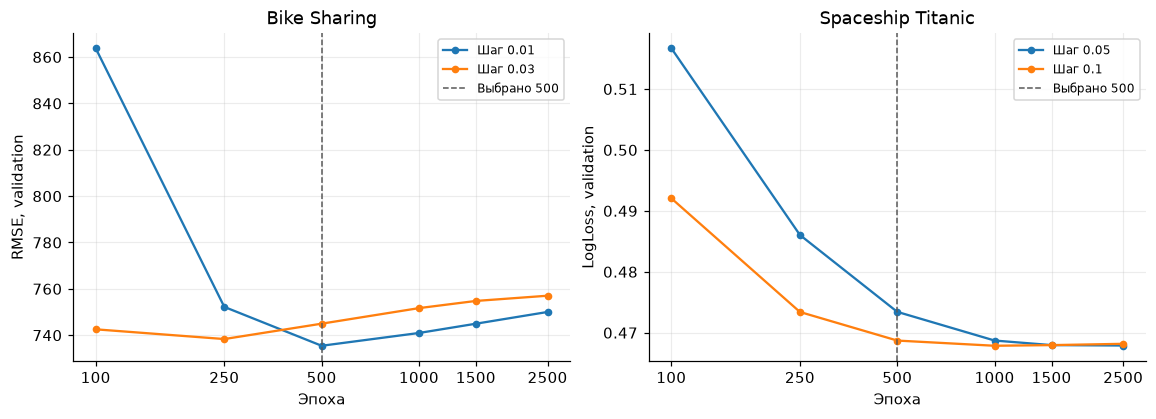

,Шаг,Эпохи,Ошибка на выбранной эпохе,Минимум из проб
Данные,,,,
Bike Sharing,0.01,500,735.459363,735.459363
Spaceship Titanic,0.10,500,0.468712,0.467859


In [3]:
EPOCH_CHECKPOINTS = np.array([100, 250, 500, 1000, 1500, 2500])
BUDGET_TOLERANCE = 0.002


def loss_values(history, metric):
    values = np.asarray(history)
    return np.sqrt(values) if metric == "RMSE" else values


def compare_budgets(model_class, features, targets, rates, metric):
    rows = []
    for rate in rates:
        model = model_class(learning_rate=rate, epochs=int(EPOCH_CHECKPOINTS[-1]))
        model.fit(features[0], targets[0], validation_data=(features[1], targets[1]))
        scores = loss_values(model.validation_loss_history_, metric)
        for epochs in EPOCH_CHECKPOINTS:
            rows.append({"Шаг": rate, "Эпохи": epochs, metric: scores[epochs - 1]})

    results = pd.DataFrame(rows)
    limit = results[metric].min() * (1 + BUDGET_TOLERANCE)
    best = results.loc[results[metric] <= limit].sort_values(["Эпохи", metric, "Шаг"]).iloc[0]
    return results, float(best["Шаг"]), int(best["Эпохи"])


bike_budget, bike_lr, bike_epochs = compare_budgets(
    LinearRegression, bike_x, bike_y, rates=[0.01, 0.03], metric="RMSE"
)
ship_budget, ship_lr, ship_epochs = compare_budgets(
    LogisticRegression, ship_x, ship_y, rates=[0.05, 0.1], metric="LogLoss"
)

fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.7), layout="constrained")
for axis, table, metric, title, epochs in [
    (axes[0], bike_budget, "RMSE", "Bike Sharing", bike_epochs),
    (axes[1], ship_budget, "LogLoss", "Spaceship Titanic", ship_epochs),
]:
    for rate, rows in table.groupby("Шаг"):
        axis.plot(rows["Эпохи"], rows[metric], marker="o", ms=4, label=f"Шаг {rate:g}")
    axis.axvline(epochs, color="0.35", ls="--", lw=1, label=f"Выбрано {epochs}")
    axis.set(xlabel="Эпоха", ylabel=f"{metric}, validation", title=title, xscale="log")
    axis.set_xticks(EPOCH_CHECKPOINTS, [str(e) for e in EPOCH_CHECKPOINTS])
    axis.minorticks_off()
    axis.legend(fontsize=8)
show_figure(fig, "epoch_budget.png")

display(pd.DataFrame([
    {"Данные": "Bike Sharing", "Шаг": bike_lr, "Эпохи": bike_epochs,
     "Ошибка на выбранной эпохе": bike_budget.loc[
         (bike_budget["Шаг"] == bike_lr) & (bike_budget["Эпохи"] == bike_epochs), "RMSE"
     ].item(), "Минимум из проб": bike_budget["RMSE"].min()},
    {"Данные": "Spaceship Titanic", "Шаг": ship_lr, "Эпохи": ship_epochs,
     "Ошибка на выбранной эпохе": ship_budget.loc[
         (ship_budget["Шаг"] == ship_lr) & (ship_budget["Эпохи"] == ship_epochs), "LogLoss"
     ].item(), "Минимум из проб": ship_budget["LogLoss"].min()},
]).set_index("Данные").round(6))

### A.3. Подбор штрафа

Для L1 перебираем положительные $\lambda_1$, для L2 — положительные $\lambda_2$, для ElasticNet — их пары. Штрафы входят в целевые функции в разных единицах: у Bike Sharing цель измеряется числом аренд и MSE считается в квадрате этих единиц, у Spaceship Titanic BCE безразмерна. Поэтому диапазоны коэффициентов для двух задач заданы отдельно. Все кандидаты внутри датасета получают одинаковые признаки, разбиение, начальные веса, шаг и число эпох.

In [4]:
def fit_regularization(model_class, features, targets, rate, epochs, l1_grid, l2_grid, metric):
    grids = {
        "Без штрафа": [(0.0, 0.0)],
        "L1": [(l1, 0.0) for l1 in l1_grid],
        "L2": [(0.0, l2) for l2 in l2_grid],
        "ElasticNet": product(l1_grid, l2_grid),
    }
    rows = []
    selected = {}
    for mode, grid in grids.items():
        best_score = np.inf
        for l1, l2 in grid:
            model = model_class(learning_rate=rate, epochs=epochs, l1=l1, l2=l2)
            model.fit(features[0], targets[0], validation_data=(features[1], targets[1]))
            score = loss_values(model.validation_loss_history_[-1], metric).item()
            rows.append({"Режим": mode, "λ₁": l1, "λ₂": l2, metric: score})
            if score < best_score:
                selected[mode] = model
                best_score = score

    return selected, pd.DataFrame(rows)


bike_models, bike_grid = fit_regularization(
    LinearRegression, bike_x, bike_y, bike_lr, bike_epochs,
    l1_grid=[0.25, 1, 4, 16, 64, 256],
    l2_grid=[0.0001, 0.001, 0.01, 0.1, 0.5],
    metric="RMSE",
)
ship_models, ship_grid = fit_regularization(
    LogisticRegression, ship_x, ship_y, ship_lr, ship_epochs,
    l1_grid=[0.00001, 0.0001, 0.001, 0.01, 0.1],
    l2_grid=[0.00001, 0.0001, 0.001, 0.01, 0.1],
    metric="LogLoss",
)

for title, table, metric in [
    ("Bike Sharing", bike_grid, "RMSE"),
    ("Spaceship Titanic", ship_grid, "LogLoss"),
]:
    print(title, "— результаты по validation")
    display(table.sort_values(["Режим", metric]).round(6))

Bike Sharing — результаты по validation


,Режим,λ₁,λ₂,RMSE
24,ElasticNet,4.00,0.0100,734.885443
19,ElasticNet,1.00,0.0100,734.940749
14,ElasticNet,0.25,0.0100,734.967384
23,ElasticNet,4.00,0.0010,735.040642
22,ElasticNet,4.00,0.0001,735.123420
18,ElasticNet,1.00,0.0010,735.255459
13,ElasticNet,0.25,0.0010,735.321160
17,ElasticNet,1.00,0.0001,735.353629
12,ElasticNet,0.25,0.0001,735.423330
28,ElasticNet,16.00,0.0010,735.844889


Spaceship Titanic — результаты по validation


,Режим,λ₁,λ₂,LogLoss
11,ElasticNet,0.00001,0.00001,0.468725
12,ElasticNet,0.00001,0.00010,0.468775
16,ElasticNet,0.00010,0.00001,0.468797
17,ElasticNet,0.00010,0.00010,0.468848
13,ElasticNet,0.00001,0.00100,0.469313
18,ElasticNet,0.00010,0.00100,0.469398
21,ElasticNet,0.00100,0.00001,0.469750
22,ElasticNet,0.00100,0.00010,0.469810
23,ElasticNet,0.00100,0.00100,0.470447
14,ElasticNet,0.00001,0.01000,0.476884


### A.4. Кривые обучения и итоговые метрики

На графиках показана ошибка на данных без добавки штрафа. Для читаемости видна последняя часть каждой траектории. Полная история, включая целевую функцию со штрафом, хранится в модели.

Силу сжатия сравниваем по нормам L1 и L2, максимуму `|w|` и числу почти нулевых коэффициентов. Пороги фиксированы до оценки test: 5 аренд на единицу закодированного признака для Bike Sharing и 0,01 в единицах логита для Spaceship Titanic. Свободный член исключён из подсчёта.

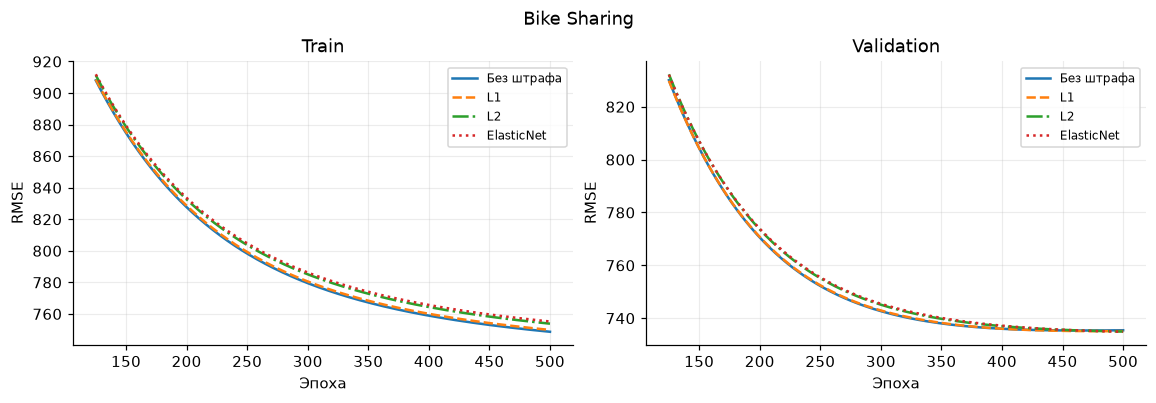

,λ₁,λ₂,Validation,MAE,RMSE,R2
Режим,,,,,,
Без штрафа,0.0,0.00,735.45936,672.98356,907.67263,0.81175
L1,4.0,0.00,735.13331,675.40083,910.72315,0.81048
L2,0.0,0.01,734.97666,677.19309,910.77141,0.81046
ElasticNet,4.0,0.01,734.88544,679.86734,913.93536,0.80914


,Норма L1,Норма L2,max |w|,Почти нулевые,Всего
Режим,,,,,
Без штрафа,11689.282,3010.574,1972.185,0,33
L1,11378.818,2985.572,1971.874,1,33
L2,11347.232,2922.569,1924.217,0,33
ElasticNet,11048.241,2898.335,1923.704,1,33


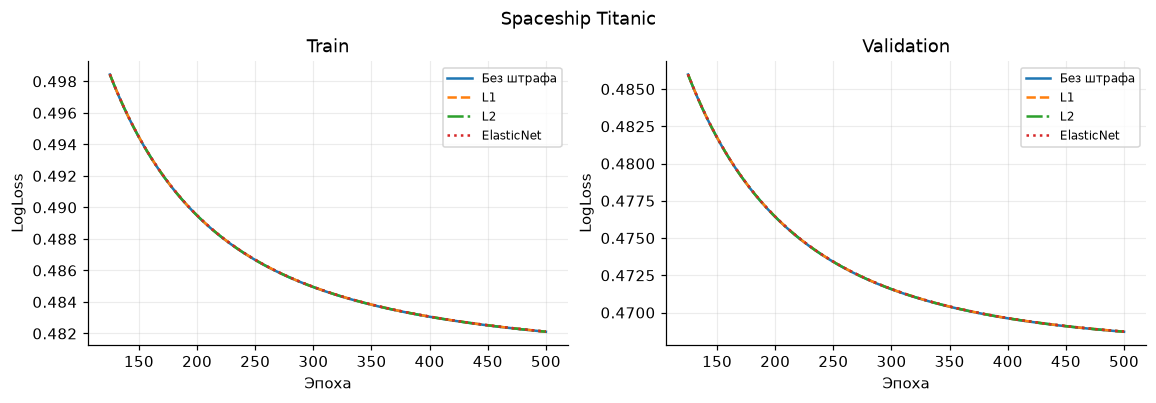

,λ₁,λ₂,Validation,Accuracy,Precision,Recall,F1,LogLoss
Режим,,,,,,,,
Без штрафа,0.00000,0.00000,0.468712,0.772858,0.767519,0.787671,0.777465,0.480348
L1,0.00001,0.00000,0.468719,0.772858,0.767519,0.787671,0.777465,0.480354
L2,0.00000,0.00001,0.468717,0.772858,0.767519,0.787671,0.777465,0.480352
ElasticNet,0.00001,0.00001,0.468725,0.772858,0.767519,0.787671,0.777465,0.480359


,Норма L1,Норма L2,max |w|,Почти нулевые,Всего
Режим,,,,,
Без штрафа,7.255,1.796,0.695,5,33
L1,7.247,1.795,0.695,6,33
L2,7.253,1.795,0.695,5,33
ElasticNet,7.245,1.794,0.695,6,33


In [5]:
def plot_regularization(models, metric, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.55), layout="constrained")
    for mode, style, model in zip(models, ["-", "--", "-.", ":"], models.values()):
        first = max(1, model.epochs // 4)
        epochs = np.arange(first, model.epochs + 1)
        for axis, history in zip(axes, [model.data_loss_history_, model.validation_loss_history_]):
            axis.plot(epochs, loss_values(history[first - 1:], metric), ls=style, lw=1.65, label=mode)
    for axis, part in zip(axes, ["Train", "Validation"]):
        axis.set(xlabel="Эпоха", ylabel=metric, title=part)
        axis.legend(fontsize=8)
    fig.suptitle(title)
    show_figure(fig, filename)


def regularization_results(models, x_test, y_test, metric, near_zero):
    scores = []
    weight_stats = []
    for mode, model in models.items():
        if metric == "RMSE":
            result = regression_metrics(y_test, model.predict(x_test))
        else:
            binary = classification_metrics(y_test, model.predict_proba(x_test), model.threshold)
            result = {name: binary[name] for name in ["Accuracy", "Precision", "Recall", "F1", "LogLoss"]}

        scores.append({
            "Режим": mode,
            "λ₁": model.l1,
            "λ₂": model.l2,
            "Validation": loss_values(model.validation_loss_history_[-1], metric).item(),
            **result,
        })
        weights = model.weights_.numpy()
        absolute = np.abs(weights)
        weight_stats.append({
            "Режим": mode,
            "Норма L1": absolute.sum(),
            "Норма L2": np.sqrt((weights ** 2).sum()),
            "max |w|": absolute.max(),
            "Почти нулевые": int((absolute < near_zero).sum()),
            "Всего": len(weights),
        })
    return pd.DataFrame(scores).set_index("Режим"), pd.DataFrame(weight_stats).set_index("Режим")


plot_regularization(bike_models, "RMSE", "Bike Sharing", "regularization_bike.png")
bike_scores, bike_weights = regularization_results(bike_models, bike_x[2], bike_y[2], "RMSE", 5.0)
display(bike_scores.round(5), bike_weights.round(3))

plot_regularization(ship_models, "LogLoss", "Spaceship Titanic", "regularization_spaceship.png")
ship_scores, ship_weights = regularization_results(ship_models, ship_x[2], ship_y[2], "LogLoss", 0.01)
display(ship_scores.round(6), ship_weights.round(3))

### Вывод по регуляризации

На Bike Sharing пробный запуск с шагом 0,01 дал минимальный validation RMSE 735,46 на 500-й эпохе. К 2500-й эпохе ошибка выросла до 750,04. Для Spaceship Titanic 500 эпох при шаге 0,1 дали LogLoss 0,468712. Это на 0,182% выше минимума 0,467859 на 1000-й эпохе и укладывается в допуск 0,2%.

На Bike Sharing ElasticNet уменьшил норму L2 весов с 3010,57 до 2898,34. Validation RMSE снизился с 735,46 до 734,89, а на test вырос с 907,67 до 913,94. Варианты с L1 получили по одному почти нулевому весу из 33. На Spaceship Titanic минимальный LogLoss получен без штрафа, а лучшие положительные коэффициенты оказались на нижней границе сетки. Варианты с L1 получили 6 почти нулевых весов против 5 без штрафа. При сильном L2 validation RMSE вырос до 1043,47 при λ₂ = 0,5 на Bike Sharing, а validation LogLoss — до 0,535196 при λ₂ = 0,1 на Spaceship Titanic. Сжатие весов в этих опытах сопровождалось разным изменением ошибки на validation и test.

## B. KNN для классификации Dry Bean

Объект — измерения одного зерна, цель — сорт в столбце `Class`. Признаки числовые, в том числе размеры и безразмерные характеристики формы. Удаляем точные повторы и стратифицируем разбиение по сорту. Сравниваем те же признаки в исходных единицах и после стандартизации.

В `fit` сохраняем обучающие строки и ответы. Для запроса $x$ вычисляем расстояние до каждой строки $u$ из train.

$$
d_{\text{Euclidean}}(x,u) = \sqrt{\sum_j (x_j-u_j)^2},
\qquad
d_{\text{Manhattan}}(x,u) = \sum_j |x_j-u_j|.
$$

Индексы сортируются по расстоянию. При равном расстоянии сохраняется порядок train. У $k$ ближайших соседей берём самый частый класс, при равенстве голосов выбираем первый класс в алфавитном порядке.

In [6]:
bean_path = DATA / "Dry_Bean_Dataset" / "Dry_Bean_Dataset.arff"
bean_columns = []
with bean_path.open(encoding="utf-8-sig") as source:
    for line in source:
        line = line.strip()
        if line.lower().startswith("@attribute "):
            bean_columns.append(line.split()[1])
        if line.lower() == "@data":
            break
    beans = pd.read_csv(source, names=bean_columns, header=None, comment="%")

print(f"Строки: {len(beans)} · признаки: {beans.shape[1] - 1} · пропуски: {beans.isna().sum().sum()}")
print("Точных повторов:", int(beans.duplicated().sum()))
beans = beans.drop_duplicates().reset_index(drop=True)
bean_raw = beans.drop(columns="Class")
bean_target = beans["Class"].to_numpy()
bean_split = random_split_indices(len(beans), labels=bean_target, seed=SEED)
bean_y = tuple(bean_target[part] for part in bean_split)
bean_labels = np.unique(bean_y[0])

display(pd.DataFrame({
    name: pd.Series(values).value_counts().reindex(bean_labels)
    for name, values in zip(PARTITIONS, bean_y)
}).rename_axis("Сорт"))
display(pd.Series(split_sizes(bean_split, len(beans)), name="Объекты"))
display(bean_raw[["Area", "Perimeter", "Eccentricity", "ShapeFactor1"]].agg(["min", "max"]).T)

Строки: 13611 · признаки: 16 · пропуски: 0
Точных повторов: 68


,Train,Validation,Test
Сорт,,,
BARBUNYA,792,265,265
BOMBAY,312,105,105
CALI,978,326,326
DERMASON,2127,709,710
HOROZ,1116,372,372
SEKER,1215,406,406
SIRA,1581,527,528


Train         8121
Validation    2710
Test          2712
Name: Объекты, dtype: int64

,min,max
Area,20420.000000,254616.000000
Perimeter,524.736000,1985.370000
Eccentricity,0.218951,0.911423
ShapeFactor1,0.002778,0.010451


### B.1. Подбор $k$, расстояния и scaling

Для каждой комбинации расстояния и предобработки считаем ближайших соседей до максимального $k$ один раз. Для меньших $k$ берём начало того же упорядоченного списка. У всех вариантов одни и те же индексы train и validation. Масштаб признаков оценивается по train с делением на стандартное отклонение ($\mathrm{ddof}=0$).

Основной критерий Dry Bean — максимальный Macro F1. У каждого из семи сортов одинаковый вклад в среднее. Accuracy считаем дополнительно. При равном критерии берём меньшее $k$, затем Euclidean и вариант без scaling при полном равенстве.

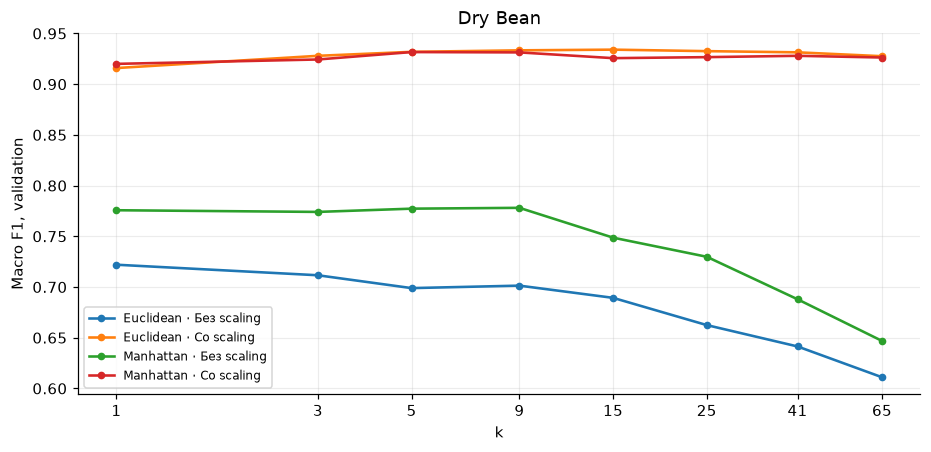

,distance,scaling,k,Accuracy,Macro F1
0,euclidean,Со scaling,15,0.92140,0.93404
1,manhattan,Со scaling,5,0.92066,0.93165
2,manhattan,Без scaling,9,0.77675,0.77808
3,euclidean,Без scaling,1,0.72177,0.72200


In [7]:
K_VALUES = [1, 3, 5, 9, 15, 25, 41, 65]
SCALE_NAMES = {False: "Без scaling", True: "Со scaling"}


def prepare_knn_features(frame, indices, preprocessor):
    preprocessor.fit(frame.iloc[indices[0]])
    return {
        scaling: tuple(
            preprocessor.transform(frame.iloc[part], scale_numeric=scaling) for part in indices
        )
        for scaling in [False, True]
    }


def validate_knn(features, targets, task, labels=None):
    rows = []
    for scaling, (x_train, x_val, _) in features.items():
        for distance in ["euclidean", "manhattan"]:
            model = KNN(k=max(K_VALUES), task=task, distance=distance).fit(x_train, targets[0])
            neighbors = model.kneighbors(x_val)
            for k in K_VALUES:
                predictions = model.predict_from_neighbors(neighbors[:, :k])
                if task == "classification":
                    scores = multiclass_metrics(targets[1], predictions, labels)
                else:
                    scores = regression_metrics(targets[1], predictions)
                rows.append({"distance": distance, "scaling": scaling, "k": k, **scores})

    results = pd.DataFrame(rows)
    metric = "Macro F1" if task == "classification" else "RMSE"
    return results.sort_values(
        [metric, "k", "distance", "scaling"],
        ascending=[task == "regression", True, True, True],
    ).reset_index(drop=True)


def show_knn_comparison(results, metric, title, filename):
    fig, axis = plt.subplots(figsize=(8.35, 4.0), layout="constrained")
    for (distance, scaling), group in results.groupby(["distance", "scaling"]):
        points = group.sort_values("k")
        axis.plot(points["k"], points[metric], "o-", ms=4, lw=1.7,
                  label=f"{distance.title()} · {SCALE_NAMES[scaling]}")
    axis.set(xscale="log", xlabel="k", ylabel=f"{metric}, validation", title=title)
    axis.set_xticks(K_VALUES, [str(k) for k in K_VALUES])
    axis.minorticks_off()
    axis.legend(fontsize=8)
    show_figure(fig, filename)

    best_by_setup = results.groupby(["distance", "scaling"], sort=False).head(1).copy()
    best_by_setup["scaling"] = best_by_setup["scaling"].map(SCALE_NAMES)
    display(best_by_setup.reset_index(drop=True).round(5))


bean_features = prepare_knn_features(bean_raw, bean_split, TabularPreprocessor(bean_raw.columns))
bean_search = validate_knn(bean_features, bean_y, "classification", bean_labels)
show_knn_comparison(bean_search, "Macro F1", "Dry Bean", "knn_dry_bean.png")

### B.2. Оценка на test

Строки confusion matrix соответствуют истинным сортам, столбцы — предсказанным. По диагонали расположены верные ответы. Для класса `c` число `TP` берём с диагонали, `FN` — из остальных ячеек строки, `FP` — из остальных ячеек столбца. Macro F1 — среднее значений `2·TP / (2·TP + FP + FN)` по всем сортам.

Euclidean · Со scaling · k=15


,Accuracy,Macro F1
Test,0.92294,0.93529


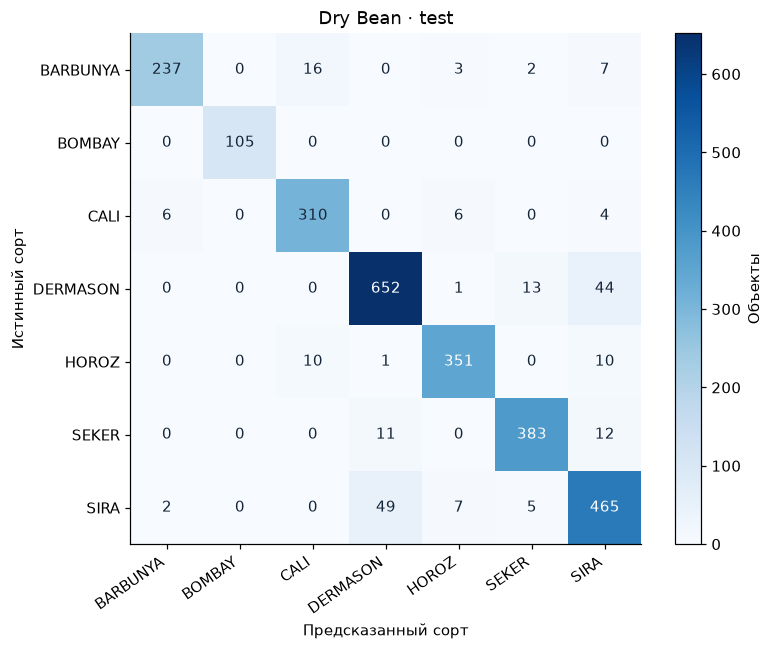

In [8]:
def predict_knn_on_test(selected, features, targets, task):
    x_train, _, x_test = features[bool(selected["scaling"])]
    model = KNN(k=int(selected["k"]), task=task, distance=selected["distance"])
    return model.fit(x_train, targets[0]).predict(x_test)


bean_choice = bean_search.iloc[0]
bean_predictions = predict_knn_on_test(bean_choice, bean_features, bean_y, "classification")
bean_test = multiclass_metrics(bean_y[2], bean_predictions, bean_labels)
print(f"{bean_choice['distance'].title()} · {SCALE_NAMES[bean_choice['scaling']]} · k={bean_choice['k']}")
display(pd.DataFrame([bean_test], index=["Test"]).round(5))

bean_matrix = confusion_matrix(bean_y[2], bean_predictions, bean_labels)
fig, axis = plt.subplots(figsize=(7.35, 5.8), layout="constrained")
axis.grid(False)
image = axis.imshow(bean_matrix, cmap="Blues")
axis.set_xticks(np.arange(len(bean_labels)), bean_labels, rotation=35, ha="right")
axis.set_yticks(np.arange(len(bean_labels)), bean_labels)
axis.set(xlabel="Предсказанный сорт", ylabel="Истинный сорт", title="Dry Bean · test")
for (row, column), count in np.ndenumerate(bean_matrix):
    axis.text(column, row, str(count), ha="center", va="center",
              color="white" if count > bean_matrix.max() / 2 else "#152538")
fig.colorbar(image, ax=axis, label="Объекты")
show_figure(fig, "dry_bean_confusion.png")

### Вывод по Dry Bean

Стандартизация при фиксированных Euclidean и k = 15 подняла validation Macro F1 с 0,6893 до 0,9340. Лучший Manhattan со scaling достиг 0,9317 при k = 5. Выбран Euclidean со scaling и k = 15. На test Accuracy составила 0,9229, Macro F1 — 0,9353. Наиболее частая пара ошибок — SIRA и DERMASON: 49 зёрен SIRA отнесены к DERMASON и 44 в обратном направлении. Все 105 зёрен BOMBAY на test распознаны верно.

## C. KNN для регрессии Seoul Bike

Объект — один час, цель — `Rented Bike Count`. Для проверки прогноза на более позднем периоде выделяем первые 60% дат под train, следующие 20% под validation, последние 20% под test. Все часы одного дня остаются в одной части. Дата служит ключом разбиения, погода и номер часа подаются как числа, сезон, праздник и работа проката кодируются one-hot.

Сохраняем часы, когда прокат закрыт. Использование `Functioning Day` предполагает известный режим работы. Модель проверяется на исторических погодных наблюдениях.

In [9]:
seoul = pd.read_csv(DATA / "SeoulBikeData.csv", encoding="cp1252")
seoul["Date"] = pd.to_datetime(seoul["Date"], format="%d/%m/%Y")
seoul = seoul.sort_values(["Date", "Hour"]).reset_index(drop=True)
print(f"Строки: {len(seoul)} · дней: {seoul['Date'].nunique()} · пропуски: {seoul.isna().sum().sum()}")
print(f"Часы без работы проката: {seoul['Functioning Day'].eq('No').sum()}")
display(seoul["Rented Bike Count"].describe().round(2))

seoul_split = chronological_day_split_indices(seoul["Date"])
seoul_sizes = split_sizes(seoul_split, len(seoul))
seoul_target = seoul["Rented Bike Count"].to_numpy()
seoul_y = tuple(seoul_target[part] for part in seoul_split)
seoul_dates = [seoul["Date"].iloc[part] for part in seoul_split]
assert seoul_dates[0].max() < seoul_dates[1].min() < seoul_dates[2].min()
assert seoul_dates[1].max() < seoul_dates[2].min()
display(pd.DataFrame({
    "Даты с": [part.min().date() for part in seoul_dates],
    "Даты по": [part.max().date() for part in seoul_dates],
    "Дней": [part.nunique() for part in seoul_dates],
    "Часов": list(seoul_sizes.values()),
}, index=PARTITIONS))

seoul_raw = seoul.drop(columns=["Date", "Rented Bike Count"])
seoul_categories = ["Seasons", "Holiday", "Functioning Day"]
seoul_numeric = [column for column in seoul_raw.columns if column not in seoul_categories]
seoul_preprocessor = TabularPreprocessor(seoul_numeric, categorical_columns=seoul_categories)
seoul_features = prepare_knn_features(seoul_raw, seoul_split, seoul_preprocessor)
print("Категории сезонов в train:", ", ".join(seoul_preprocessor.categories_["Seasons"]))

Строки: 8760 · дней: 365 · пропуски: 0
Часы без работы проката: 295


count    8760.00
mean      704.60
std       645.00
min         0.00
25%       191.00
50%       504.50
75%      1065.25
max      3556.00
Name: Rented Bike Count, dtype: float64

,Даты с,Даты по,Дней,Часов
Train,2017-12-01,2018-07-07,219,5256
Validation,2018-07-08,2018-09-18,73,1752
Test,2018-09-19,2018-11-30,73,1752


Категории сезонов в train: Spring, Summer, Winter


### C.1. Выбор модели и сравнение с baseline

Для регрессии $\hat{y}$ — среднее ответов $k$ ближайших соседей. Настройки выбираем по минимальному RMSE на validation на той же сетке, что в части B. Базовый прогноз на каждый час равен среднему числу аренд по train. Считаем MAE, RMSE и $R^2$ для KNN и baseline на одном test.

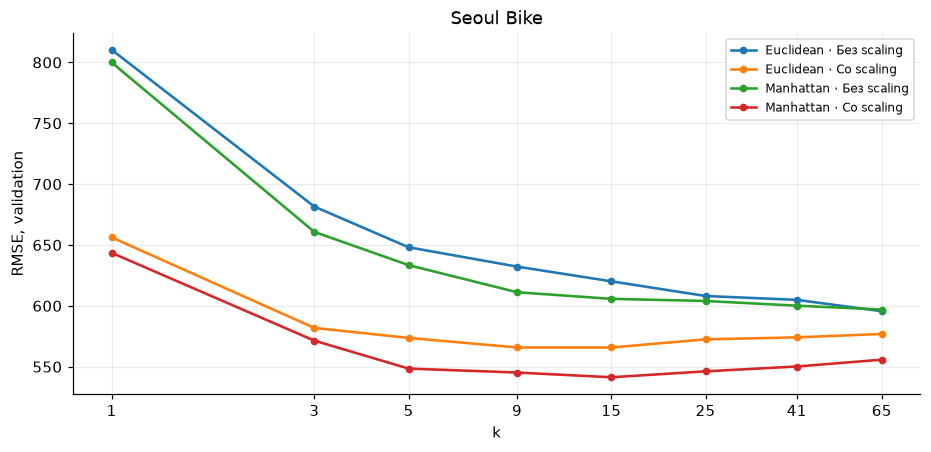

,distance,scaling,k,MAE,RMSE,R2
0,manhattan,Со scaling,15,421.75632,541.36609,0.27578
1,euclidean,Со scaling,15,443.06396,565.81721,0.20889
2,euclidean,Без scaling,65,487.18757,595.60889,0.12338
3,manhattan,Без scaling,65,495.57950,596.96282,0.11939


Manhattan · Со scaling · k=15
Постоянный прогноз baseline: 600.92


,MAE,RMSE,R2
KNN,342.46773,510.07511,0.30837
Среднее train,507.69385,632.87924,-0.06476


In [10]:
seoul_search = validate_knn(seoul_features, seoul_y, "regression")
show_knn_comparison(seoul_search, "RMSE", "Seoul Bike", "knn_seoul.png")

seoul_choice = seoul_search.iloc[0]
seoul_predictions = predict_knn_on_test(seoul_choice, seoul_features, seoul_y, "regression")
baseline_predictions = np.full(len(seoul_y[2]), seoul_y[0].mean())
seoul_test = pd.DataFrame([
    regression_metrics(seoul_y[2], seoul_predictions),
    regression_metrics(seoul_y[2], baseline_predictions),
], index=["KNN", "Среднее train"])
print(f"{seoul_choice['distance'].title()} · {SCALE_NAMES[seoul_choice['scaling']]} · k={seoul_choice['k']}")
print(f"Постоянный прогноз baseline: {baseline_predictions[0]:.2f}")
display(seoul_test.round(5))

### Вывод по Seoul Bike

При k = 15 стандартизация уменьшила validation RMSE с 605,78 до 541,37 для Manhattan. При тех же k и scaling Euclidean дал 565,82. Выбран Manhattan со scaling и k = 15. На test RMSE KNN составил 510,08 против 632,88 у постоянного прогноза среднего train, снижение на 19,4%. MAE снизилась с 507,69 до 342,47, R² вырос с −0,0648 до 0,3084.

Test целиком приходится на осень, а осень не представлена в train. Блок сезона для неё состоит из нулей. В test также 223 часа закрытия проката против 24 в validation. Полученные метрики относятся к конкретному переходу между периодами и исторической погоде.

## Источники данных

- [Bike Sharing Dataset](https://www.kaggle.com/datasets/marklvl/bike-sharing-dataset)
- [Spaceship Titanic](https://www.kaggle.com/competitions/spaceship-titanic/data)
- [Dry Bean Dataset](https://doi.org/10.24432/C50S4B)
- [Seoul Bike Sharing Demand](https://doi.org/10.24432/C5F62R)